# Randomized testing: pursuit with collision avoidance

`virtual_testing.ipynb` runs eight hand-picked scenarios. This notebook runs **hundreds of randomly generated ones** through the same `PursuitAvoidance` controller, so rare failures show up and settings can be compared on the same set of trials.

**What is randomized** (all ranges are in `RandomizationSpec`, in `randomized_testing.py`):
- where the pursuer starts
- how the runner behaves: stationary, straight line, circle, polygon, random waypoints, figure eight, "approach" (aimed at the pursuer's start), "charge" (steers at the pursuer) and "flee" (runs from it). Moving runners are acceleration-limited, so they cannot reverse instantly.
- the simulated drone's response lag, mocap latency, position noise and velocity noise
- mocap dropouts (random windows during which one drone's data stops refreshing)

**Reproducible.** One integer *seed* fixes a whole trial. `run_batch(n, seed=...)` derives all trial seeds from one master seed, and `replay(seed)` re-runs any single trial.

**Outcomes**, per trial:
| outcome | meaning |
|---|---|
| collision | the true normalized separation $q$ dropped below 1 (envelopes overlapped) |
| unexpected stop | `PursuitAvoidance` returned `'stop'` and it was *not* caused by a data dropout: the pursuer gave up and would land |
| dropout stop | a stop caused by a mocap dropout (expected) |
| completed | ran the full duration |

The ranges for lag, latency and noise are **assumptions**: none of them has been measured on your drone. The results below tell you how much each one matters, so you know what to measure first.

In [1]:
import sys, os, importlib
from dataclasses import replace, asdict
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.animation import FuncAnimation
from IPython.display import display, Markdown, HTML

%matplotlib inline

sys.path.insert(0, os.getcwd())          # this notebook lives next to randomized_testing.py
import randomized_testing as rt
rt = importlib.reload(rt)                # pick up edits without restarting the kernel
from match_config import CONFIG

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
print('Using', rt.__file__)

Using /home/claude/proj/src/randomized_testing.py


## 1. What the random scenarios look like

One example of each runner type (first matching seed). Blue is the runner, red is the pursuer. The solid circle is the envelope at the closest approach ($q = 1$) and the dashed circle includes the margin. `o` marks the start and `x` the end.

`NOMINAL` assumes a drone with at most 0.5 s lag and small mocap noise. `STRESS` uses wider ranges (up to 0.8 s lag, larger noise). Print either one to see every range.

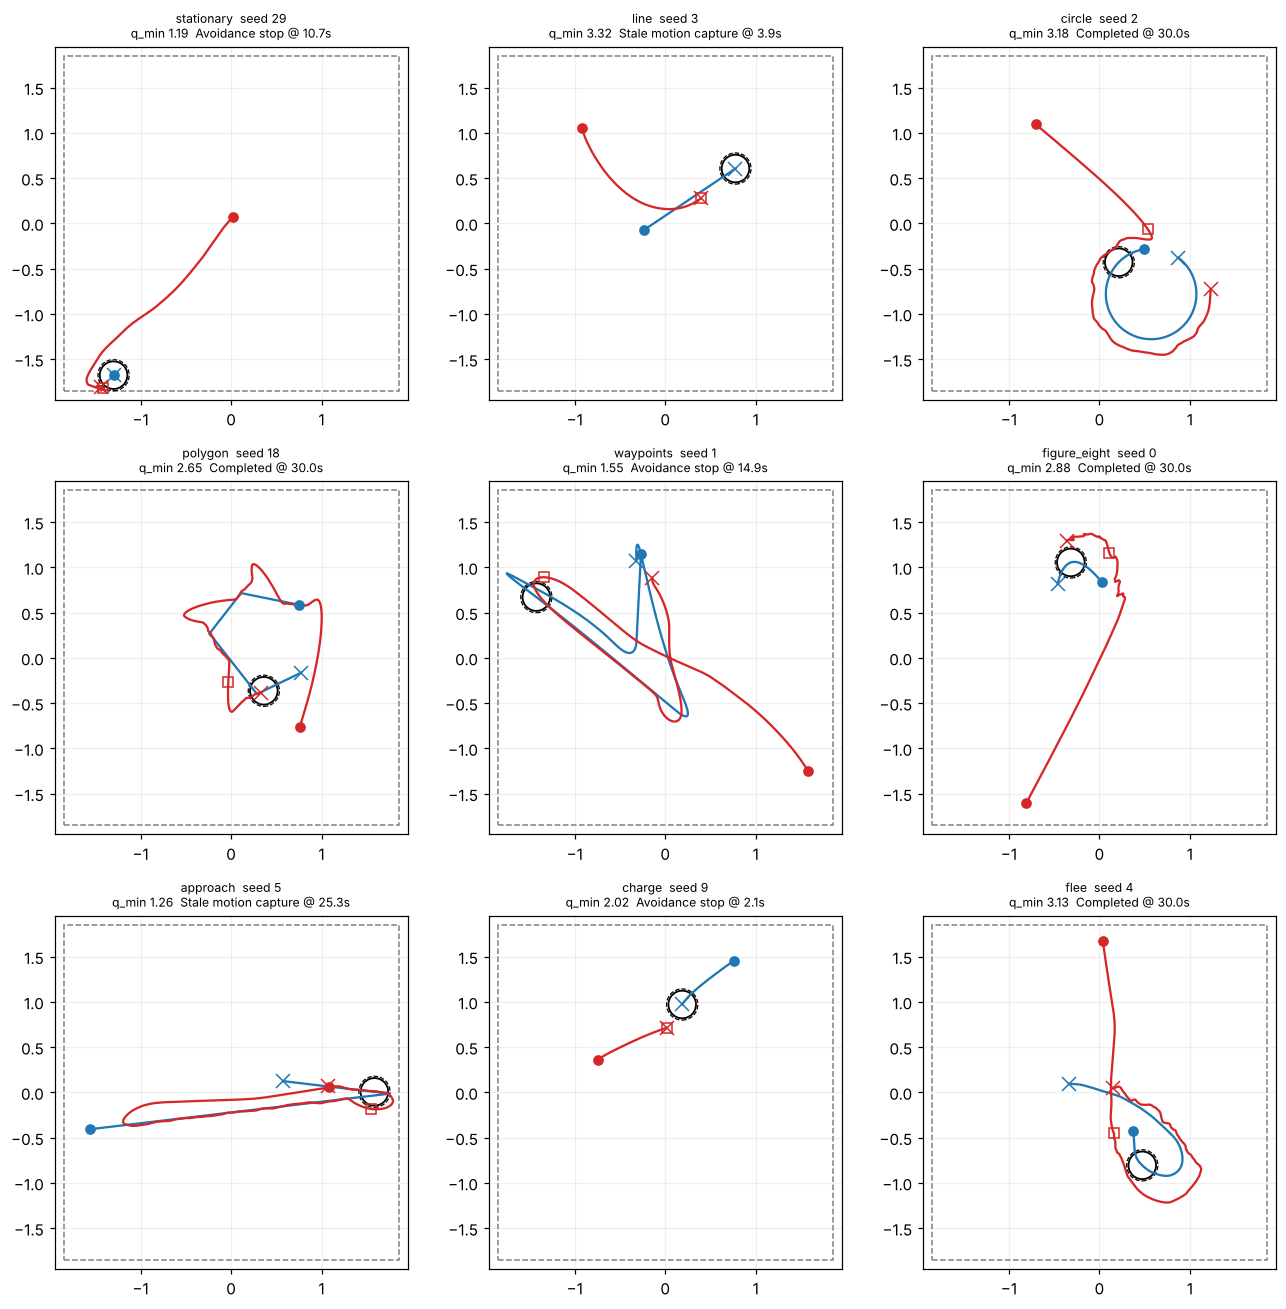

RandomizationSpec(runner_kinds={'stationary': 1, 'line': 2, 'circle': 1, 'polygon': 1, 'waypoints': 2, 'figure_eight': 1, 'approach': 2, 'charge': 1, 'flee': 1}, runner_speed=(0.05, 0.5), runner_accel=1.0, response_time=(0.2, 0.5), latency=(0.0, 0.05), pos_noise=(0.0, 0.002), vel_noise=(0.0, 0.02), dropout_prob=0.25, dropout_count=(1, 2), dropout_duration=(0.05, 0.6), dropout_start=(1.0, 25.0), min_start_separation=0.6, wall_clearance=0.1, duration=30.0)


In [2]:
spec = rt.NOMINAL
kinds = list(spec.runner_kinds)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, kind in zip(axes.ravel(), kinds):
    seed = next(s for s in range(2000) if rt.sample_trial(s, spec).kind == kind)
    trial, result = rt.replay(seed, spec)
    rt.plot_trial(result, trial, ax=ax)
fig.tight_layout(); plt.show()
print(spec)

## 2. Run a batch

The table counts outcomes per runner type. `Min q (5th pct)` is the 5th percentile of each trial's lowest $q$.

In [3]:
N, SEED = 300, 1
rows = rt.run_batch(N, seed=SEED, spec=spec, progress=False)   # about a minute
display(Markdown(rt.summary_markdown(rows)))

n_collide = sum(r['collided'] for r in rows)
print(f"Collisions (q < 1): {n_collide} of {N}.  Command or step-limit violations: {sum(not r['command_ok'] for r in rows)}.")
if n_collide == 0:
    print(f"With 0 collisions in {N} independent trials, the collision rate is below about {100 * rt.rule_of_three(N):.1f}% "
          f"(95% confidence, rule of three). That only holds for runners like the ones sampled here.")

| Runner | Trials | Collisions (q<1) | Margin zone entered | Unexpected stops | Dropout stops | Min q (worst) | Min q (5th pct) | Score zone (mean %) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| approach | 49 | 0 | 3 | 18 | 4 | 1.11 | 1.13 | 47.4 |
| charge | 26 | 0 | 4 | 26 | 0 | 1.07 | 1.10 | 0.0 |
| circle | 27 | 0 | 0 | 7 | 4 | 1.20 | 1.35 | 30.6 |
| figure_eight | 20 | 0 | 0 | 1 | 4 | 1.15 | 1.75 | 39.1 |
| flee | 24 | 0 | 0 | 0 | 3 | 1.77 | 1.98 | 66.1 |
| line | 57 | 0 | 1 | 17 | 18 | 1.12 | 1.14 | 40.1 |
| polygon | 28 | 0 | 3 | 12 | 2 | 1.11 | 1.13 | 25.8 |
| stationary | 25 | 0 | 0 | 7 | 3 | 1.15 | 1.15 | 2.0 |
| waypoints | 44 | 0 | 3 | 23 | 2 | 1.10 | 1.13 | 44.6 |
| **All** | 300 | 0 | 14 | 111 | 40 | 1.07 | 1.13 | 35.1 |

Collisions (q < 1): 0 of 300.  Command or step-limit violations: 0.
With 0 collisions in 300 independent trials, the collision rate is below about 1.0% (95% confidence, rule of three). That only holds for runners like the ones sampled here.


## 3. Outcomes

- **Left:** the lowest $q$ reached in each trial. Everything right of the red line kept the envelopes apart.
- **Middle:** how each runner type ended.
- **Right:** where the pursuer started, colored by outcome. Look for regions that fail more often.

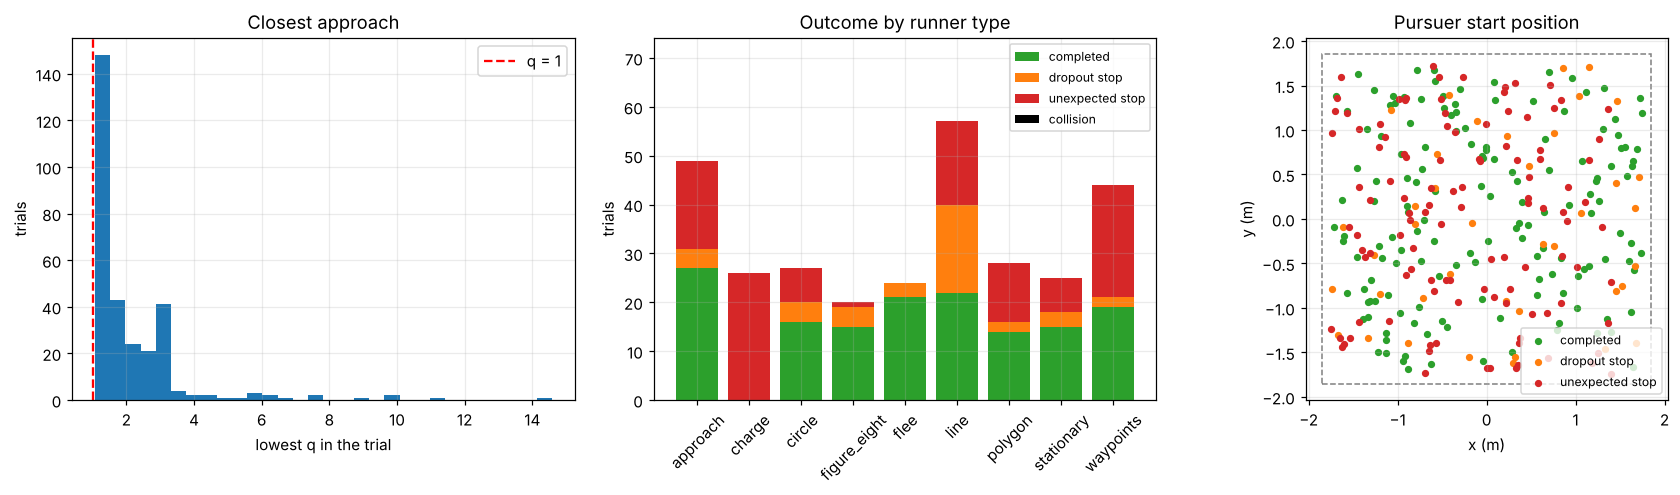

In [4]:
def outcome(r):
    if r['collided']:         return 'collision'
    if r['unexpected_stop']:  return 'unexpected stop'
    if r['dropout_related']:  return 'dropout stop'
    return 'completed'
COL = {'completed': 'tab:green', 'dropout stop': 'tab:orange', 'unexpected stop': 'tab:red', 'collision': 'black'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
q = np.array([r['q_min'] for r in rows])
axes[0].hist(q, bins=30, color='tab:blue'); axes[0].axvline(1, color='red', ls='--', label='q = 1')
axes[0].set(xlabel='lowest q in the trial', ylabel='trials', title='Closest approach'); axes[0].legend()

kinds_sorted = sorted({r['kind'] for r in rows}); bottom = np.zeros(len(kinds_sorted))
for name in COL:
    cnt = np.array([sum(outcome(r) == name for r in rows if r['kind'] == k) for k in kinds_sorted])
    axes[1].bar(kinds_sorted, cnt, bottom=bottom, color=COL[name], label=name); bottom += cnt
axes[1].set_ylim(0, bottom.max() * 1.3); axes[1].set(ylabel='trials', title='Outcome by runner type'); axes[1].tick_params(axis='x', rotation=45); axes[1].legend(fontsize=8)

lo, hi = CONFIG.lower[:2], CONFIG.upper[:2]
axes[2].add_patch(Rectangle(lo, *(hi - lo), fill=False, ls='--', color='gray'))
for name in COL:
    pts = np.array([r['start'] for r in rows if outcome(r) == name])
    if len(pts): axes[2].scatter(pts[:, 0], pts[:, 1], s=14, color=COL[name], label=name)
axes[2].set_aspect('equal'); axes[2].set(xlabel='x (m)', ylabel='y (m)', title='Pursuer start position'); axes[2].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. Which random factor drives the stops?

A second batch with the wider `STRESS` ranges, binned by each factor. If a bar is high, trials with that factor in that range stop more often. The factors are independent, so a clear trend points at that factor.

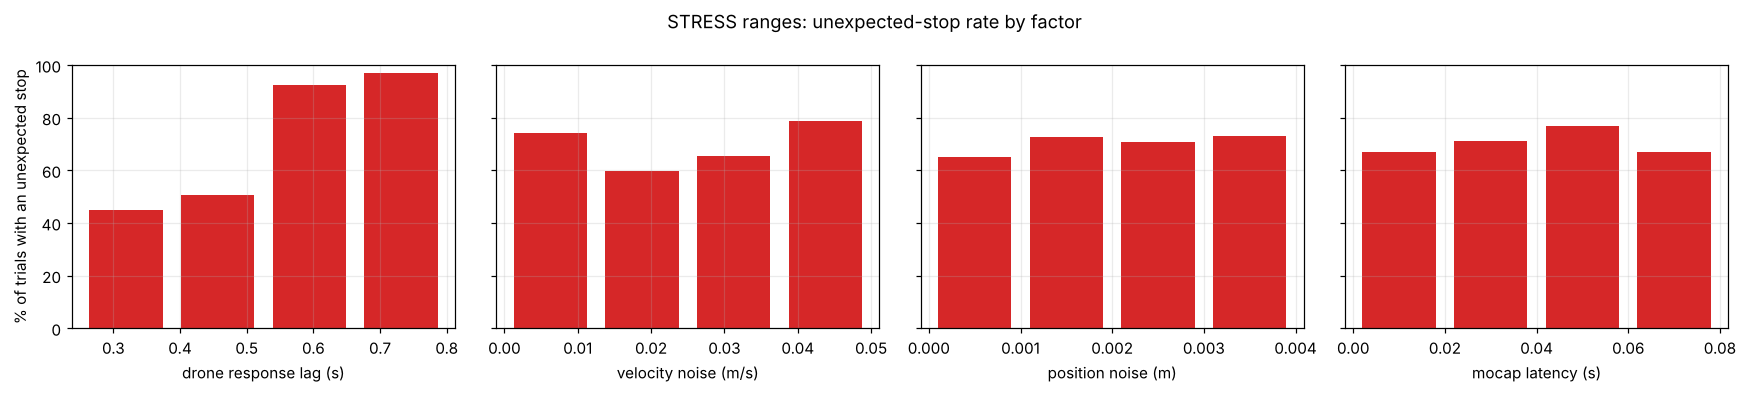

In [5]:
rows_stress = rt.run_batch(300, seed=2, spec=rt.STRESS, progress=False)
panels = [('response_time', 'drone response lag (s)', np.linspace(0.25, 0.8, 5)),
          ('vel_noise', 'velocity noise (m/s)', np.linspace(0, 0.05, 5)),
          ('pos_noise', 'position noise (m)', np.linspace(0, 0.004, 5)),
          ('latency', 'mocap latency (s)', np.linspace(0, 0.08, 5))]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (key, label, edges) in zip(axes, panels):
    v = np.array([r[key] for r in rows_stress]); u = np.array([r['unexpected_stop'] for r in rows_stress])
    rate, centers = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (v >= a) & ((v <= b) if b == edges[-1] else (v < b))
        rate.append(100 * u[m].mean() if m.any() else np.nan); centers.append(0.5 * (a + b))
    ax.bar(centers, rate, width=0.8 * (edges[1] - edges[0]), color='tab:red'); ax.set_xlabel(label)
axes[0].set_ylabel('% of trials with an unexpected stop'); axes[0].set_ylim(0, 100)
fig.suptitle('STRESS ranges: unexpected-stop rate by factor'); fig.tight_layout(); plt.show()

## 5. Look at the worst trials, and replay one

The lowest-$q$ trials are listed with their seeds. Any of them can be re-run exactly with `rt.replay(seed, spec)` (use the same `spec` as the batch). `rt.replay` returns the same `result` dictionary that `simulate()` in `virtual_testing.ipynb` returns, plus `q`, so the plotting code there works on it too.

| seed | runner | lowest q | outcome | lag (s) | latency (s) | pos noise (mm) |
|---:|---|---:|---|---:|---:|---:|
| 3866329691 | charge | 1.07 | unexpected stop | 0.36 | 0.046 | 1.3 |
| 2545692922 | waypoints | 1.10 | unexpected stop | 0.50 | 0.042 | 0.0 |
| 2516085283 | charge | 1.10 | unexpected stop | 0.26 | 0.040 | 0.3 |
| 388034923 | waypoints | 1.10 | unexpected stop | 0.27 | 0.042 | 1.0 |
| 1503172678 | polygon | 1.11 | unexpected stop | 0.23 | 0.048 | 0.3 |
| 657650772 | charge | 1.11 | unexpected stop | 0.39 | 0.029 | 1.4 |

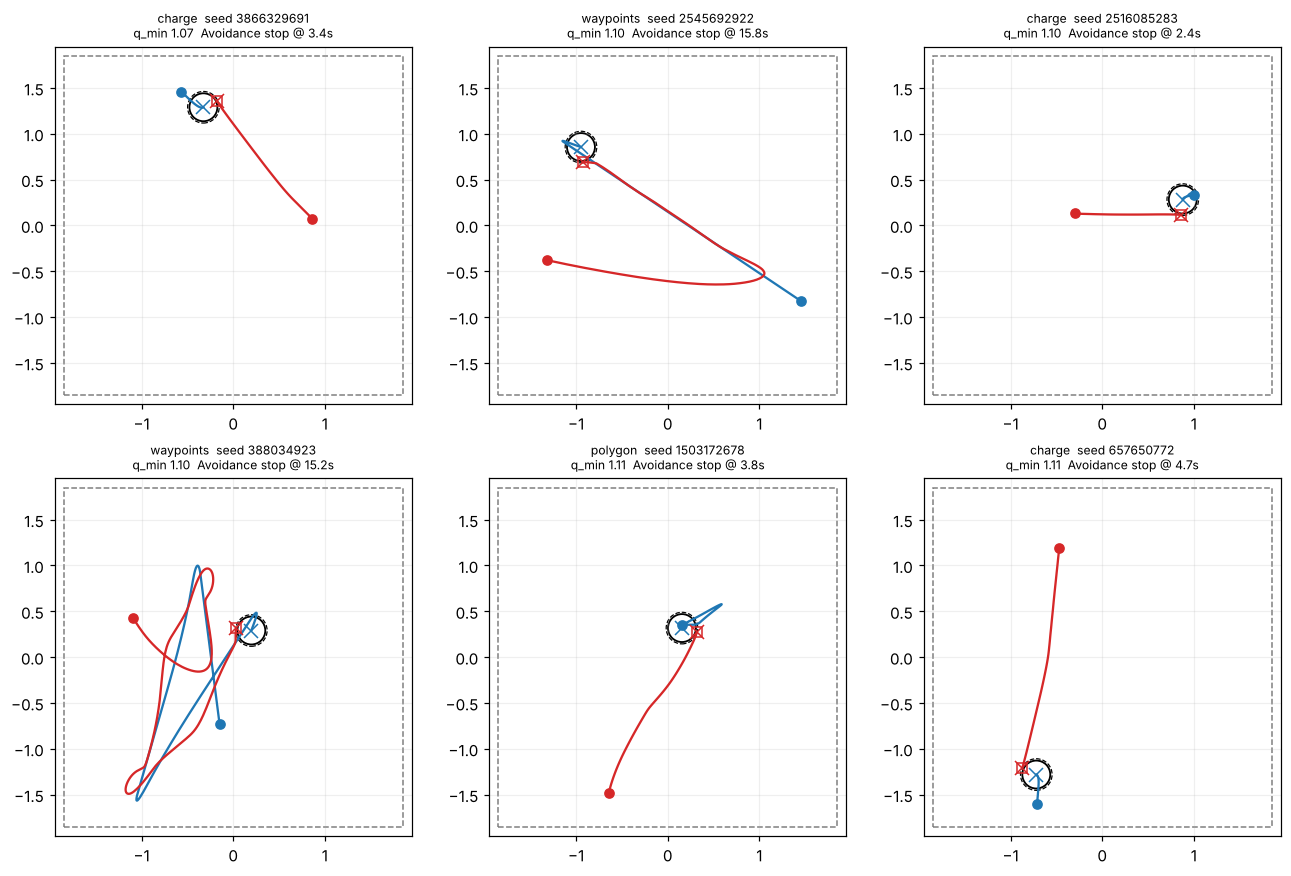

In [6]:
worst = sorted(rows, key=lambda r: r['q_min'])[:6]
display(Markdown('| seed | runner | lowest q | outcome | lag (s) | latency (s) | pos noise (mm) |\n|---:|---|---:|---|---:|---:|---:|\n' +
    '\n'.join(f"| {r['seed']} | {r['kind']} | {r['q_min']:.2f} | {outcome(r)} | {r['response_time']:.2f} | {r['latency']:.3f} | {1000*r['pos_noise']:.1f} |" for r in worst)))
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, r in zip(axes.ravel(), worst):
    trial, result = rt.replay(r['seed'], spec)
    rt.plot_trial(result, trial, ax=ax)
fig.tight_layout(); plt.show()

### Watch one trial

The first of the lowest-$q$ trials that lasted long enough to be worth watching. Press play. This is playback of the recorded simulation.

In [7]:
def animate_trial(result, trial, step=5):
    lo, hi = CONFIG.lower[:2], CONFIG.upper[:2]
    frames = np.arange(0, len(result['time']), step)
    fig, ax = plt.subplots(figsize=(4.6, 4.6), dpi=60)
    ax.add_patch(Rectangle(lo, *(hi - lo), fill=False, ls='--', color='gray'))
    ax.set_xlim(lo[0] - 0.1, hi[0] + 0.1); ax.set_ylim(lo[1] - 0.1, hi[1] + 0.1); ax.set_aspect('equal'); ax.grid(alpha=0.2)
    rd, = ax.plot([], [], 'o', color='tab:blue', label='runner'); pd_, = ax.plot([], [], 'o', color='tab:red', label='pursuer')
    rt_, = ax.plot([], [], color='tab:blue', alpha=0.35); pt_, = ax.plot([], [], color='tab:red', alpha=0.35)
    fp, = ax.plot([], [], '*', color='purple', ms=10, label='0.5 m behind')
    clock = ax.text(0.03, 0.97, '', transform=ax.transAxes, va='top'); ax.legend(loc='lower right', fontsize=8)
    ax.set_title(f"{trial.kind}, seed {trial.seed}", fontsize=9)
    def update(f):
        k = frames[f]
        rd.set_data([result['runner'][k, 0]], [result['runner'][k, 1]]); pd_.set_data([result['pursuer'][k, 0]], [result['pursuer'][k, 1]])
        rt_.set_data(result['runner'][:k + 1, 0], result['runner'][:k + 1, 1]); pt_.set_data(result['pursuer'][:k + 1, 0], result['pursuer'][:k + 1, 1])
        fp.set_data([result['follow_point'][k, 0]], [result['follow_point'][k, 1]])
        clock.set_text(f"t = {result['time'][k]:.1f} s   q = {result['q'][k]:.2f}")
        return rd, pd_, rt_, pt_, fp, clock
    anim = FuncAnimation(fig, update, frames=len(frames), interval=100, blit=False, repeat=False)
    plt.close(fig); return anim

pick = next(r for r in worst if r['stop_time'] > 3.0)
trial, result = rt.replay(pick['seed'], spec)
HTML(animate_trial(result, trial).to_jshtml())

## 6. Compare settings on the *same* trials

Because a trial is defined by its seed, two controller settings can be run on identical scenarios and compared directly (a paired comparison). Pass a modified `config` or a simulator option to `run_batch`; the seeds do not change.

### 6a. Response lag against `max_lead`

`PursuitAvoidance` only allows commands within `max_lead` (0.35 m) of the *measured* drone. At full speed a laggy drone trails its setpoint by roughly speed $\times$ lag, so once that exceeds `max_lead` no command is feasible, even in open space. The runners here have no noise or dropouts, so the stops come from lag alone.

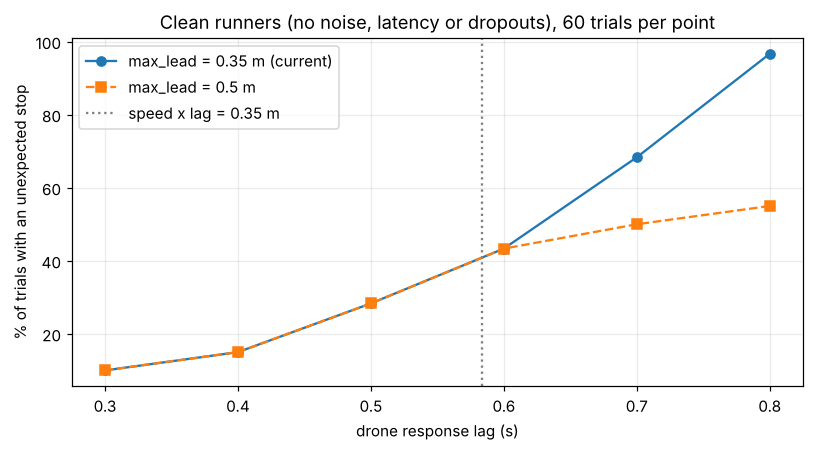

In [8]:
lags = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
clean = lambda lag: rt.RandomizationSpec(response_time=(lag, lag), latency=(0, 0), pos_noise=(0, 0), vel_noise=(0, 0),
                                         dropout_prob=0.0, runner_kinds={'stationary': 1, 'line': 1, 'circle': 1, 'figure_eight': 1, 'flee': 1})
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for max_lead, style in [(0.35, 'o-'), (0.5, 's--')]:
    cfg = replace(CONFIG, max_lead=max_lead)
    rates = [100 * np.mean([r['unexpected_stop'] for r in rt.run_batch(60, seed=7, spec=clean(lag), config=cfg, progress=False)]) for lag in lags]
    ax.plot(lags, rates, style, label=f'max_lead = {max_lead} m' + (' (current)' if max_lead == 0.35 else ''))
ax.axvline(0.35 / CONFIG.horizontal_speed, color='gray', ls=':', label='speed x lag = 0.35 m')
ax.set(xlabel='drone response lag (s)', ylabel='% of trials with an unexpected stop', title='Clean runners (no noise, latency or dropouts), 60 trials per point')
ax.legend(); fig.tight_layout(); plt.show()

### 6b. Runner-velocity deadband (stationary runner)

A stationary runner should never cause a stop, but mocap noise makes its estimated velocity non-zero, which flips the follow direction. Treating runner velocities below a threshold as zero (`runner_velocity_deadband`) is a possible fix. This tests it on the same 40 stationary-runner trials per setting. (The deadband is an option of the simulator only: to use it in flight you would apply the same rule in `flight.py` before `travel_direction` and `avoidance.step`.)

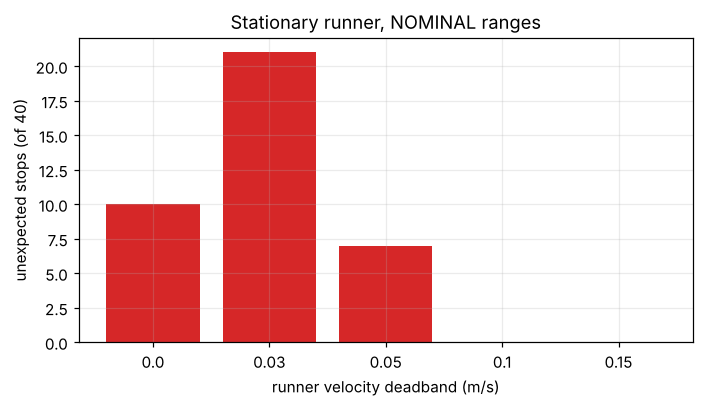

{0.0: 10, 0.03: 21, 0.05: 7, 0.1: 0, 0.15: 0}


In [9]:
stationary = replace(rt.NOMINAL, runner_kinds={'stationary': 1})
deadbands = [0.0, 0.03, 0.05, 0.1, 0.15]
stops = [sum(r['unexpected_stop'] for r in rt.run_batch(40, seed=3, spec=stationary, progress=False, runner_velocity_deadband=d)) for d in deadbands]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar([str(d) for d in deadbands], stops, color='tab:red'); ax.set(xlabel='runner velocity deadband (m/s)', ylabel='unexpected stops (of 40)', title='Stationary runner, NOMINAL ranges')
fig.tight_layout(); plt.show()
print(dict(zip(deadbands, stops)))

## 7. Using this as a regression test

Add a cell like this to `virtual_testing.ipynb` (or run it before a flight) so a controller change that breaks safety is caught:

```python
import randomized_testing as rt
rows = rt.run_batch(300, seed=1, spec=rt.NOMINAL)
assert not any(r['collided'] for r in rows), [r['seed'] for r in rows if r['collided']]
assert all(r['command_ok'] for r in rows)
```

**Limits to keep in mind**
- The lag, latency and noise ranges, the runner models and the scoring-zone definition (behind the runner, 0.3 to 0.6 m, within 15 degrees) are assumptions. Measure the drone's response to a setpoint step and the mocap noise on a stationary drone, then narrow the ranges.
- The runners never try to avoid the pursuer (except `flee`, which runs away) and `charge` is deliberately hostile. Zero collisions here says nothing about an opponent running its own avoidance.
- The simulated drone is a first-order lag with no inertia, overshoot or tilt limits.
- The collision check uses the true positions at a fixed height; altitude differences are not simulated.